# Dataset Exploration — IC4SD-Wood-Conifer20v1

**Phase -1**: Understand raw data before organizing for Phase 0.

> **Note**: This notebook follows a fixed template for scalability and reproducibility.

## 1. Metadata

In [8]:
# Configuration
RAW_DATA_PATH = "../../data/raw"
OUTPUT_DIR = "../../data/exploration"

# Create output directory
import os
os.makedirs(OUTPUT_DIR, exist_ok=True)

In [9]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

plt.style.use("seaborn-v0_8-darkgrid")
sns.set_palette("husl")

## 2. Folder Structure Analysis

In [10]:
# List all folders in raw data
folders = [f for f in os.listdir(RAW_DATA_PATH) 
           if os.path.isdir(os.path.join(RAW_DATA_PATH, f)) 
           and not f.startswith('.')]
print(f"Total folders: {len(folders)}")
print("\nAll folders:")
for f in sorted(folders):
    print(f"  - {f}")

Total folders: 21

All folders:
  - 3244.Calocedrus sp
  - 3252.Callitris columellaris
  - 3273.Fokienia hodginsii
  - 3274.Cunninghamia lanceolata
  - 3314.Cupressus funebris (Cupressus pendula)
  - 3325.Pinus sp
  - 3341.Xanthocyparis vietnamensis
  - 3342.Calocedrus rupestris
  - 3350.Cryptomeria japonica
  - 3351.Araucaria araucana
  - 3364.Chamaecyparis obtusa
  - 3378.Picea glauca
  - 3379.Pinus radiata
  - 3383.Pseudotsuga brevifolia
  - 3384.Pinus krempfii
  - 3385.Pinus cernua
  - 3386.Podocarpus pilgeri
  - 3387.Thujopsis dolabrata
  - 3391.Taxus wallichiana
  - 3393.Pinus dalatensis
  - __MACOSX


## 3. Species Distribution

In [11]:
# Count images per folder
def count_images(folder_path):
    """Count image files in folder and subfolders."""
    image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
    count = 0
    for root, dirs, files in os.walk(folder_path):
        for f in files:
            if Path(f).suffix.lower() in image_extensions:
                count += 1
    return count

# Build species DataFrame
species_data = []
for folder in sorted(folders):
    folder_path = os.path.join(RAW_DATA_PATH, folder)
    image_count = count_images(folder_path)
    species_data.append({
        'folder_code': folder.split('.')[0],
        'species_name': '.'.join(folder.split('.')[1:]).strip(),
        'full_name': folder,
        'image_count': image_count
    })

df_species = pd.DataFrame(species_data)
print(df_species.to_string(index=False))
print(f"\nTotal images: {df_species['image_count'].sum()}")

folder_code                           species_name                                   full_name  image_count
       3244                          Calocedrus sp                          3244.Calocedrus sp          238
       3252                 Callitris columellaris                 3252.Callitris columellaris          416
       3273                     Fokienia hodginsii                     3273.Fokienia hodginsii          412
       3274                Cunninghamia lanceolata                3274.Cunninghamia lanceolata          450
       3314 Cupressus funebris (Cupressus pendula) 3314.Cupressus funebris (Cupressus pendula)          318
       3325                               Pinus sp                               3325.Pinus sp          216
       3341             Xanthocyparis vietnamensis             3341.Xanthocyparis vietnamensis          318
       3342                   Calocedrus rupestris                   3342.Calocedrus rupestris          302
       3350                 

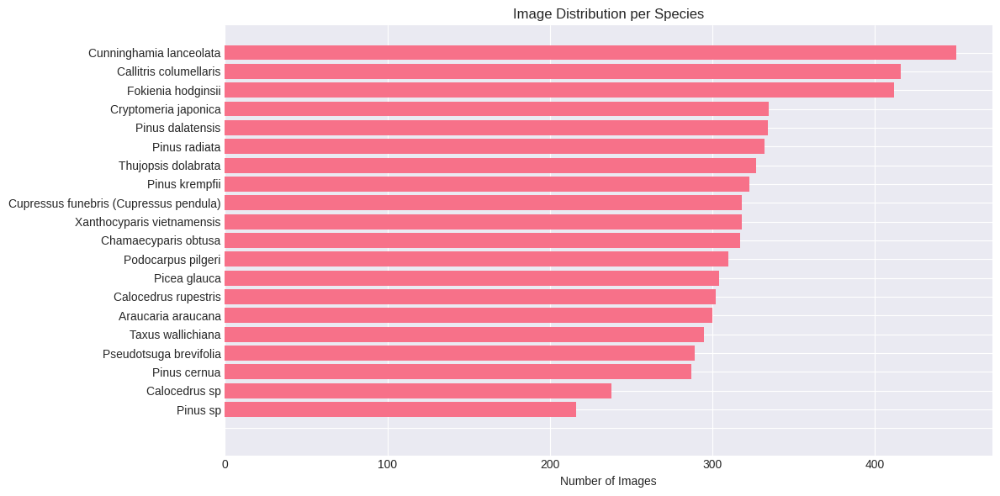

In [12]:
# Visualize distribution
fig, ax = plt.subplots(figsize=(12, 6))
df_sorted = df_species.sort_values('image_count', ascending=True)
ax.barh(df_sorted['species_name'], df_sorted['image_count'])
ax.set_xlabel('Number of Images')
ax.set_title('Image Distribution per Species')
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/species_distribution.png", dpi=150)
plt.show()

## 4. Image Analysis

In [13]:
# Check image properties (sample first 100 images)
from PIL import Image

image_sizes = []
sample_images = (
    glob.glob(os.path.join(RAW_DATA_PATH, "**/*.jpg"), recursive=True) +
    glob.glob(os.path.join(RAW_DATA_PATH, "**/*.png"), recursive=True)
)[:100]

for img_path in sample_images:
    try:
        with Image.open(img_path) as img:
            width, height = img.size
            mode = img.mode
            image_sizes.append({
                'path': img_path,
                'width': width,
                'height': height,
                'mode': mode,
                'aspect_ratio': width / height
            })
    except Exception as e:
        print(f"Error reading {img_path}: {e}")

df_images = pd.DataFrame(image_sizes)
print(df_images.describe())

        width  height  aspect_ratio
count   100.0   100.0        100.00
mean   2560.0  2048.0          1.25
std       0.0     0.0          0.00
min    2560.0  2048.0          1.25
25%    2560.0  2048.0          1.25
50%    2560.0  2048.0          1.25
75%    2560.0  2048.0          1.25
max    2560.0  2048.0          1.25


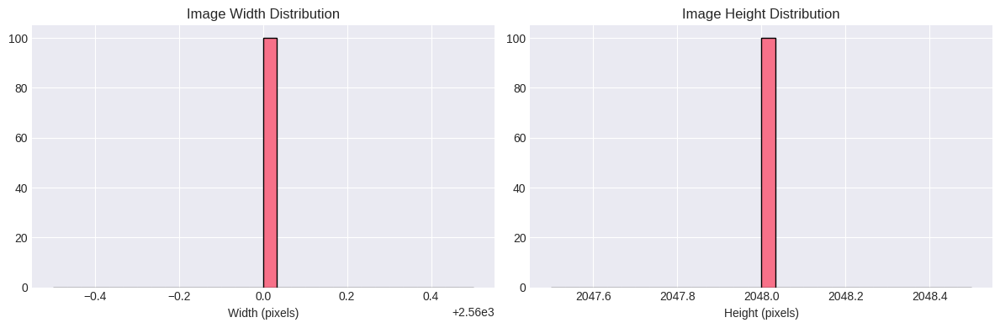

In [14]:
# Visualize image size distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_images['width'], bins=30, edgecolor='black')
axes[0].set_xlabel('Width (pixels)')
axes[0].set_title('Image Width Distribution')

axes[1].hist(df_images['height'], bins=30, edgecolor='black')
axes[1].set_xlabel('Height (pixels)')
axes[1].set_title('Image Height Distribution')

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/image_sizes.png", dpi=150)
plt.show()

## 5. Sample Images per Species

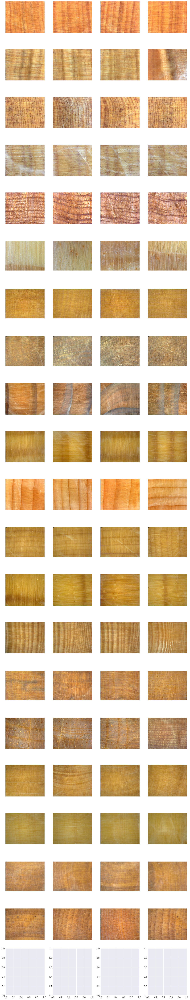

In [15]:
# Display 4 sample images per species
def get_sample_images(folder_path, n=4):
    """Get n sample image paths from folder."""
    image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
    images = []
    for root, dirs, files in os.walk(folder_path):
        for f in files:
            if Path(f).suffix.lower() in image_extensions:
                images.append(os.path.join(root, f))
                if len(images) >= n:
                    return images
    return images[:n]

# Display samples
n_cols = 4
n_rows = len(folders)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3 * n_rows))

for idx, folder in enumerate(sorted(folders)):
    folder_path = os.path.join(RAW_DATA_PATH, folder)
    samples = get_sample_images(folder_path, n_cols)
    
    for col, img_path in enumerate(samples):
        try:
            img = Image.open(img_path)
            axes[idx, col].imshow(img)
            axes[idx, col].axis('off')
            if col == 0:
                axes[idx, col].set_ylabel(folder.split('.')[-1][:20], fontsize=8, rotation=0, labelpad=50)
        except Exception as e:
            axes[idx, col].text(0.5, 0.5, 'Error', ha='center', va='center')
            axes[idx, col].axis('off')

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/sample_images.png", dpi=100, bbox_inches='tight')
plt.show()

## 6. Ambiguous Labels Analysis

In [16]:
# Identify potentially ambiguous labels
ambiguous = df_species[df_species['species_name'].str.contains(r'sp\.|×|x\s|hybrid', case=False, regex=True)]
print("Potentially ambiguous species (contains 'sp.', '×', 'x ', 'hybrid'):")
print(ambiguous.to_string(index=False))

# Check for duplicates or near-duplicates
print("\n\nChecking for potential duplicates:")
species_lower = df_species['species_name'].str.lower()
for i, name1 in enumerate(species_lower):
    for j, name2 in enumerate(species_lower[i+1:], i+1):
        if name1 in name2 or name2 in name1:
            print(f"  - '{df_species.iloc[i]['species_name']}' vs '{df_species.iloc[j]['species_name']}'")

Potentially ambiguous species (contains 'sp.', '×', 'x ', 'hybrid'):
Empty DataFrame
Columns: [folder_code, species_name, full_name, image_count]
Index: []


Checking for potential duplicates:
  - 'Calocedrus sp' vs ''
  - 'Callitris columellaris' vs ''
  - 'Fokienia hodginsii' vs ''
  - 'Cunninghamia lanceolata' vs ''
  - 'Cupressus funebris (Cupressus pendula)' vs ''
  - 'Pinus sp' vs ''
  - 'Xanthocyparis vietnamensis' vs ''
  - 'Calocedrus rupestris' vs ''
  - 'Cryptomeria japonica' vs ''
  - 'Araucaria araucana' vs ''
  - 'Chamaecyparis obtusa' vs ''
  - 'Picea glauca' vs ''
  - 'Pinus radiata' vs ''
  - 'Pseudotsuga brevifolia' vs ''
  - 'Pinus krempfii' vs ''
  - 'Pinus cernua' vs ''
  - 'Podocarpus pilgeri' vs ''
  - 'Thujopsis dolabrata' vs ''
  - 'Taxus wallichiana' vs ''
  - 'Pinus dalatensis' vs ''


## 7. Quality Issues Check

In [17]:
# Check for corrupted images (sample 50 from each species)
corrupted = []
all_images = glob.glob(os.path.join(RAW_DATA_PATH, "**/*.jpg"), recursive=True)
sample_for_check = all_images[::max(1, len(all_images)//100)][:100]  # Sample ~100 images

for img_path in sample_for_check:
    try:
        with Image.open(img_path) as img:
            img.verify()  # Verify it's a valid image
    except Exception as e:
        corrupted.append({'path': img_path, 'error': str(e)})

if corrupted:
    print(f"Found {len(corrupted)} potentially corrupted images:")
    for c in corrupted[:10]:
        print(f"  - {c['path']}: {c['error']}")
else:
    print("No corrupted images found in sample.")

No corrupted images found in sample.


## 8. Compare with Reference Documents

In [18]:
# Reference species list from tree.txt
REFERENCE_SPECIES = [
    # Cupressaceae
    "cunninghamia_lanceolata",
    "callitris_columellaris",
    "fokienia_hodginsii",
    "cupressus_funebris",
    "calocedrus_sp",
    "cryptomeria_japonica",
    "xanthocyparis_vietnamensis",
    "chamaecyparis_obtusa",
    # Pinaceae
    "pinus_dalatensis",
    "pinus_radiata",
    "pinus_sp",
    "pinus_krempfii",
    "picea_glauca",
    "araucaria_araucana",
    "pseudotsuga_brevifolia",
    "pinus_cernua",
    # Podocarpaceae
    "podocarpus_pilgeri",
    # Taxaceae
    "taxus_wallichiana",
]

# Compare with actual folder names
actual_species = [s.lower().replace(' ', '_').replace('-', '_').replace('(', '').replace(')', '') 
                  for s in df_species['species_name']]

print("Species in dataset vs reference:")
print("-" * 60)
for ref in sorted(REFERENCE_SPECIES):
    status = "✓" if any(ref in act for act in actual_species) else "✗ MISSING"
    print(f"{status} {ref}")

Species in dataset vs reference:
------------------------------------------------------------
✓ araucaria_araucana
✓ callitris_columellaris
✓ calocedrus_sp
✓ chamaecyparis_obtusa
✓ cryptomeria_japonica
✓ cunninghamia_lanceolata
✓ cupressus_funebris
✓ fokienia_hodginsii
✓ picea_glauca
✓ pinus_cernua
✓ pinus_dalatensis
✓ pinus_krempfii
✓ pinus_radiata
✓ pinus_sp
✓ podocarpus_pilgeri
✓ pseudotsuga_brevifolia
✓ taxus_wallichiana
✓ xanthocyparis_vietnamensis


## 8b. UMAP Visualization — Families & Species

Use a pretrained **ResNet-50** (ImageNet) as a feature extractor.
Apply **UMAP** to project the penultimate-layer embeddings (2048-d) into 2D,
then color the scatter plot by **family** (4 classes) and **species** (20 classes).

> This gives an early indication of how separable the families / species are
> in deep-feature space *before* any fine-tuning.

In [27]:
# ── 8b-1  Extract features with pretrained ResNet-50 ────────────────
import torch
import os
import torchvision.transforms as T
import torchvision.models as models
from PIL import Image
from tqdm.auto import tqdm

# Species → Family mapping (from WoodID_plan.md, Section 3.2)
SPECIES_TO_FAMILY = {
    "Cunninghamia lanceolata": "Cupressaceae",
    "Callitris columellaris":  "Cupressaceae",
    "Fokienia hodginsii":      "Cupressaceae",
    "Cupressus funebris":      "Cupressaceae",
    "Calocedrus sp":           "Cupressaceae",
    "Cryptomeria japonica":    "Cupressaceae",
    "Xanthocyparis vietnamensis": "Cupressaceae",
    "Chamaecyparis obtusa":    "Cupressaceae",
    "Calocedrus rupestris":    "Cupressaceae",
    "Thujopsis dolabrata":     "Cupressaceae",
    "Pinus dalatensis":        "Pinaceae",
    "Pinus radiata":           "Pinaceae",
    "Pinus sp":                "Pinaceae",
    "Pinus krempfii":          "Pinaceae",
    "Picea glauca":            "Pinaceae",
    "Araucaria araucana":      "Pinaceae",
    "Pseudotsuga brevifolia":  "Pinaceae",
    "Pinus cernua":            "Pinaceae",
    "Podocarpus pilgeri":      "Podocarpaceae",
    "Taxus wallichiana":       "Taxaceae",
}

# Helper: parse folder name → species name
def folder_to_species(folder_name):
    """E.g. '3274.Cunninghamia lanceolata' → 'Cunninghamia lanceolata'"""
    parts = folder_name.split(".", 1)
    if len(parts) == 2:
        species = parts[1].strip()
        # Remove parenthetical synonyms
        if "(" in species:
            species = species[:species.index("(")].strip()
        return species
    return folder_name

# Load pretrained EfficientNet-B3 (feature extractor: drop final FC)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
efficient = models.efficientnet_b3(weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)

efficient.classifier = torch.nn.Identity()  # output 1024-d
efficient = efficient.to(device).eval()

transform = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406],
                std=[0.229, 0.224, 0.225]),
])

# Collect image paths with labels
import random
random.seed(42)

MAX_PER_SPECIES = 100  # sample up to 100 images per species for speed
image_extensions = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}

all_paths, all_species, all_families = [], [], []
valid_folders = sorted([f for f in os.listdir(RAW_DATA_PATH)
                        if os.path.isdir(os.path.join(RAW_DATA_PATH, f))
                        and not f.startswith('.') and f != '__MACOSX'])

for folder in valid_folders:
    species = folder_to_species(folder)
    family = SPECIES_TO_FAMILY.get(species, None)
    if family is None:
        print(f"⚠ No family mapping for: {species} (folder={folder})")
        continue

    folder_path = os.path.join(RAW_DATA_PATH, folder)
    imgs = []
    for root, _, files in os.walk(folder_path):
        for f in files:
            if Path(f).suffix.lower() in image_extensions:
                imgs.append(os.path.join(root, f))

    if len(imgs) > MAX_PER_SPECIES:
        imgs = random.sample(imgs, MAX_PER_SPECIES)

    all_paths.extend(imgs)
    all_species.extend([species] * len(imgs))
    all_families.extend([family] * len(imgs))

print(f"Total images to embed: {len(all_paths)} "
      f"({len(set(all_species))} species, {len(set(all_families))} families)")

# Extract features
features = []
with torch.no_grad():
    for path in tqdm(all_paths, desc="Extracting features"):
        img = Image.open(path).convert("RGB")
        x = transform(img).unsqueeze(0).to(device)
        feat = efficient(x).squeeze(0).cpu().numpy()
        features.append(feat)

features = np.stack(features)
print(f"Feature matrix: {features.shape}")


Total images to embed: 2000 (20 species, 4 families)


Extracting features: 100%|██████████| 2000/2000 [02:04<00:00, 16.03it/s]

Feature matrix: (2000, 1536)


/home/sakana/miniconda3/envs/wood/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP embedding: (2000, 2)


/tmp/ipykernel_29030/200671343.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_20 = plt.cm.get_cmap("tab20", len(species_list))


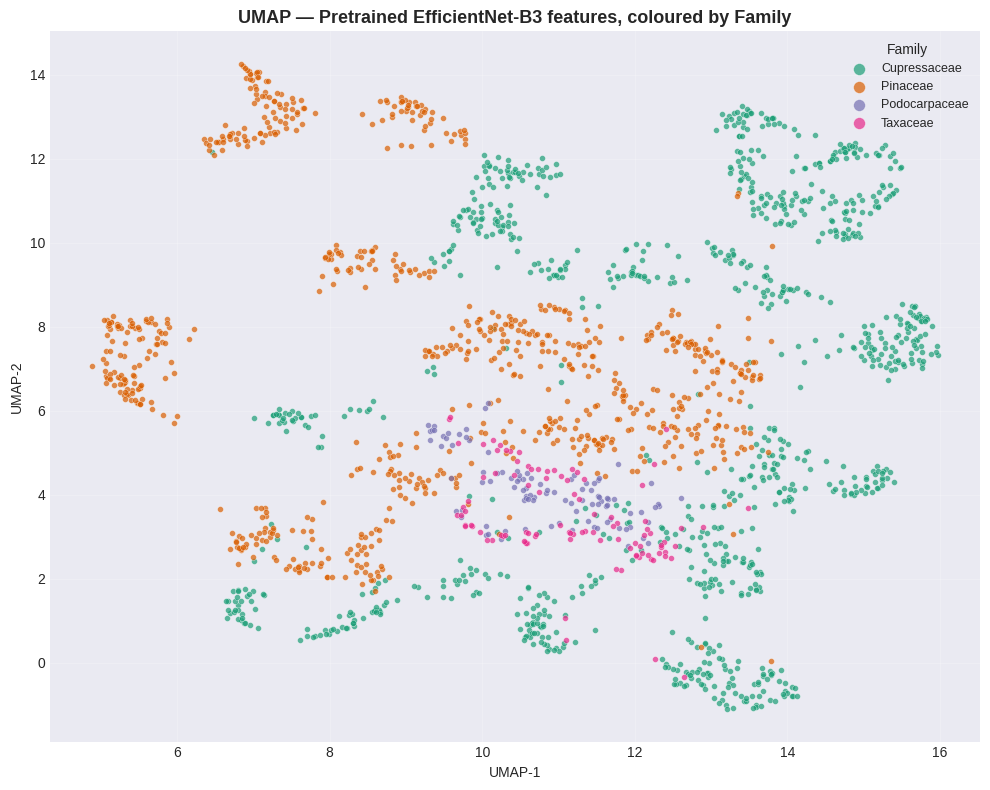

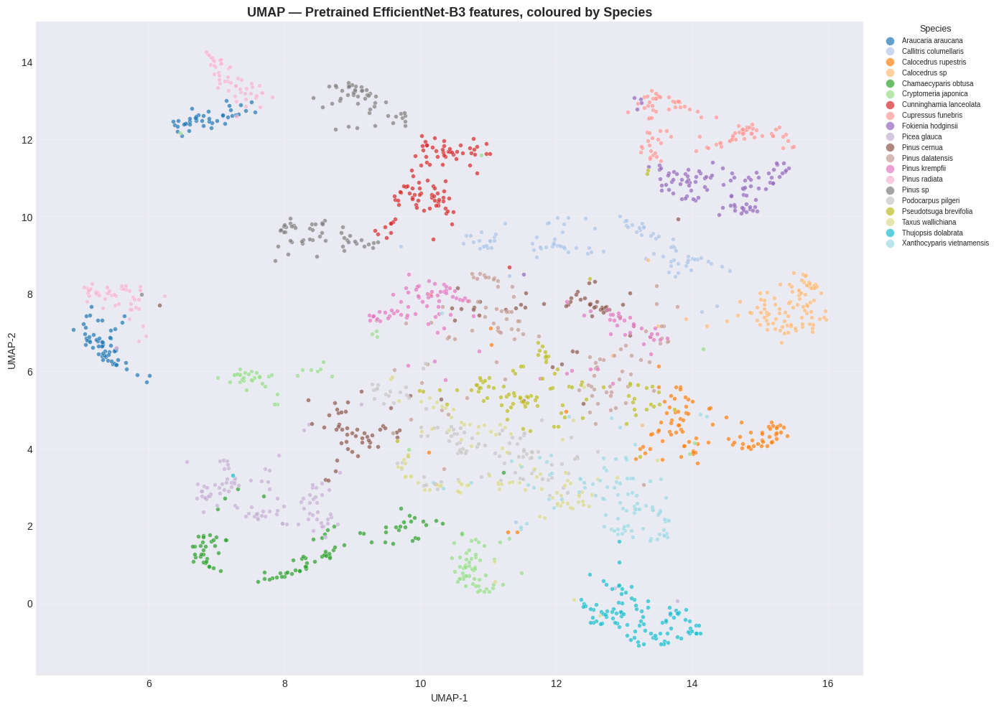


✓ UMAP figures saved to: ../../data/exploration/umap_family.png ../../data/exploration/umap_species.png


In [28]:
# ── 8b-2  UMAP projection & visualization ─────────────────────────
from umap import UMAP

reducer = UMAP(
    n_components=2, n_neighbors=15, min_dist=0.3, metric="cosine", random_state=42
)
embedding = reducer.fit_transform(features)
print(f"UMAP embedding: {embedding.shape}")

# ── Colour palettes ────────────────────────────────────────────────
FAMILY_COLORS = {
    "Cupressaceae": "#1b9e77",
    "Pinaceae": "#d95f02",
    "Podocarpaceae": "#7570b3",
    "Taxaceae": "#e7298a",
}

# Assign a distinct colour per species, grouped by family hue
from matplotlib.colors import to_hex
import matplotlib.cm as cm

species_list = sorted(set(all_species))
# Use a wide qualitative palette
cmap_20 = plt.cm.get_cmap("tab20", len(species_list))
SPECIES_COLORS = {sp: to_hex(cmap_20(i)) for i, sp in enumerate(species_list)}

# ── Figure 1: colour by FAMILY (4 classes) ─────────────────────────
fig, ax = plt.subplots(figsize=(10, 8))
for family, color in FAMILY_COLORS.items():
    mask = np.array([f == family for f in all_families])
    ax.scatter(
        embedding[mask, 0],
        embedding[mask, 1],
        c=color,
        label=family,
        s=18,
        alpha=0.7,
        edgecolors="w",
        linewidths=0.3,
    )
ax.set_title(
    "UMAP — Pretrained EfficientNet-B3 features, coloured by Family",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("UMAP-1")
ax.set_ylabel("UMAP-2")
ax.legend(title="Family", fontsize=9, title_fontsize=10, markerscale=2, framealpha=0.9)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/umap_family.png", dpi=150, bbox_inches="tight")
plt.show()

# ── Figure 2: colour by SPECIES (20 classes) ──────────────────────
fig, ax = plt.subplots(figsize=(14, 10))
for species in species_list:
    mask = np.array([s == species for s in all_species])
    ax.scatter(
        embedding[mask, 0],
        embedding[mask, 1],
        c=SPECIES_COLORS[species],
        label=species,
        s=18,
        alpha=0.7,
        edgecolors="w",
        linewidths=0.3,
    )
ax.set_title(
    "UMAP — Pretrained EfficientNet-B3 features, coloured by Species",
    fontsize=13,
    fontweight="bold",
)
ax.set_xlabel("UMAP-1")
ax.set_ylabel("UMAP-2")
ax.legend(
    title="Species",
    fontsize=7,
    title_fontsize=9,
    markerscale=2,
    framealpha=0.9,
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0,
)
ax.grid(True, alpha=0.2)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/umap_species.png", dpi=150, bbox_inches="tight")
plt.show()

print(
    "\n✓ UMAP figures saved to:",
    f"{OUTPUT_DIR}/umap_family.png",
    f"{OUTPUT_DIR}/umap_species.png",
)

## 9. Conclusions & Recommendations

### Findings Summary

**TODO**: Fill in after exploration completes.

1. **Dataset Statistics**:
   - Total folders/species:
   - Total images:
   - Image size range:

2. **Family Distribution**:
   - Cupressaceae: X species, Y images
   - Pinaceae: X species, Y images
   - Podocarpaceae: X species, Y images
   - Taxaceae: X species, Y images

3. **Ambiguous Labels**:
   - List ambiguous species here

4. **Quality Issues**:
   - Any corrupted images?
   - Size inconsistencies?

5. **Recommendations for Phase 0**:
   - Species-to-family mapping
   - Handling of ambiguous labels
   - Split strategy

## 10. Export Summary

In [21]:
# Export summary as JSON for Phase 0
import json

summary = {
    'total_species': len(df_species),
    'total_images': int(df_species['image_count'].sum()),
    'species_list': df_species.to_dict('records'),
    'ambiguous_species': ambiguous['species_name'].tolist() if len(ambiguous) > 0 else [],
    'image_size_range': {
        'min_width': int(df_images['width'].min()),
        'max_width': int(df_images['width'].max()),
        'min_height': int(df_images['height'].min()),
        'max_height': int(df_images['height'].max()),
    },
    'corrupted_images': len(corrupted)
}

with open(f"{OUTPUT_DIR}/exploration_summary.json", 'w') as f:
    json.dump(summary, f, indent=2)

print(f"Summary exported to {OUTPUT_DIR}/exploration_summary.json")
df_species.to_csv(f"{OUTPUT_DIR}/species_list.csv", index=False)
print(f"Species list exported to {OUTPUT_DIR}/species_list.csv")

Summary exported to ../../data/exploration/exploration_summary.json
Species list exported to ../../data/exploration/species_list.csv
